El dataset se encuentra en: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2


Para poder usarlo sin necesidad de descargarlo completamente se utiliza kagglehub.

```python
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)
```

El primer paso es instalar la biblioteca `kagglehub`.

Ahora importamos las librerias que nos hacen falta.

In [7]:
import kagglehub
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from PIL import Image
import random
import json
import pickle
import warnings
warnings.filterwarnings('ignore') # This line will ignore all warnings

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

Una vez tenemos esto debemos identificarnos para poder acceder a los datos.

In [8]:
# Autenticación con Kaggle
kagglehub.login()

# Descargar dataset
print("Descargando dataset...")
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"✅ Dataset descargado en: {path}")
except Exception as e:
    print(f"❌ Error: {e}")
    raise

Descargando dataset...
Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
✅ Dataset descargado en: /kaggle/input/garbage-classification-v2
Kaggle credentials set.
Kaggle credentials successfully validated.


Ya podemos descargar el dataset completo.

In [9]:
# Paso 4: Descargar el dataset

# Usamos el dataset de garbage classification (el más popular para empezar)
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"\n¡Dataset descargado correctamente!")
    print(f"Ubicación: {path}")
except Exception as e:
    print(f"\nError al descargar: {e}")
    print("Alternativa: Intentando con otro dataset...")
    try:
        path = kagglehub.dataset_download("mostafaabla/garbage-classification")
        print(f"\n¡Dataset alternativo descargado!")
        print(f"Ubicación: {path}")
    except Exception as e2:
        print(f"\nTambién falló: {e2}")
        raise

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.

¡Dataset descargado correctamente!
Ubicación: /kaggle/input/garbage-classification-v2


## Preprocesamiento: Eliminación de Fondo y Fondo Gris Uniforme

Para mejorar el enfoque del modelo en los objetos de basura y estandarizar las imágenes, vamos a realizar el siguiente preprocesamiento:
1.  **Segmentación:** Utilizaremos la librería `rembg` para detectar y eliminar el objeto principal de la imagen (la basura) de su fondo original.
2.  **Fondo Uniforme:** Sustituiremos el fondo original por un color gris medio-oscuro uniforme.
3.  **Nueva Estructura:** Guardaremos las imágenes procesadas en una nueva carpeta, manteniendo la misma estructura de clases.

Este proceso puede tardar un tiempo considerable (aproximadamente 30-60 minutos para todo el dataset), ya que se procesa imagen por imagen. Se recomienda ejecutarlo y dejarlo trabajar.

In [ ]:
import sys
!{sys.executable} -m pip install rembg[cpu]
!{sys.executable} -m pip install --upgrade pillow

from rembg import remove
from PIL import Image
import numpy as np
import os
import time
from tqdm.notebook import tqdm
import cv2 # Importar OpenCV para el cálculo de bounding boxes

ORIGINAL_DATA_PATH = "/kaggle/input/garbage-classification-v2/standardized_384"
PROCESSED_DATA_ROOT = "/kaggle/working/garbage_yolo_dataset" # Nueva ruta para el dataset procesado en formato YOLO

# Subdirectorios para imágenes y etiquetas dentro del dataset YOLO
YOLO_IMAGES_DIR = os.path.join(PROCESSED_DATA_ROOT, "images")
YOLO_LABELS_DIR = os.path.join(PROCESSED_DATA_ROOT, "labels")

# Color gris medio-oscuro (RGB) para el fondo
GRAY_BACKGROUND = (70, 70, 70)

# Mapeo de clases a IDs numéricos para YOLO
# Asegurarse de que esta lista de clases_objetivo coincida con la usada anteriormente
YOLO_CLASS_MAP = {
    'organico': 0,
    'papel_carton': 1,
    'vidrio': 2,
    'plastico': 3
}

# Definir el mapeo de las 10 clases a las 4 categorías
mapeo_clases = {
    # Orgánico
    'biological': 'organico',

    # Papel/Cartón
    'cardboard': 'papel_carton',
    'paper': 'papel_carton',

    # Vidrio
    'glass': 'vidrio',

    # Plástico
    'plastic': 'plastico',

    # Nota: Las siguientes clases NO serán incluidas en el modelo de 4 clases
    # 'battery': No incluida (residuos peligrosos)
    # 'clothes': No incluida (textiles)
    # 'metal': No incluida (metal)
    # 'shoes': No incluida (calzado)
    # 'trash': No incluida (basura general)
}

# Nuestras 4 clases objetivo
clases_objetivo = ['organico', 'papel_carton', 'vidrio', 'plastico']

# Colores para visualización (aunque no se usan en esta celda, se mueven con el mapeo por contexto)
colores_clases = {
    'organico': '#e74c3c',
    'papel_carton': '#3498db',
    'vidrio': '#2ecc71',
    'plastico': '#f1c40f'
}

def process_image_for_yolo(input_path, output_image_path, output_label_path, class_id, bg_color=GRAY_BACKGROUND):
    """
    Procesa una imagen: elimina el fondo, reemplaza con un fondo gris,
    calcula y guarda el bounding box en formato YOLO.
    """
    # Cargar imagen usando OpenCV para mayor robustez y luego convertir a PIL
    img_cv2 = cv2.imread(input_path)
    if img_cv2 is None: # Si OpenCV no pudo cargar la imagen
        raise IOError(f"No se pudo cargar la imagen con OpenCV: {input_path}")

    # Convertir de BGR (OpenCV) a RGB (PIL) y luego a objeto PIL Image
    img_cv2_rgb = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_cv2_rgb).convert("RGBA")

    # Eliminar fondo usando rembg
    img_no_bg_rgba = remove(img_pil, session_name='u2net')

    # Extraer canal alfa para encontrar el objeto
    alpha_channel = np.array(img_no_bg_rgba)[:, :, 3]

    # Encontrar contornos del objeto
    # Convertir a formato adecuado para findContours (8-bit single-channel image)
    alpha_8bit = cv2.threshold(alpha_channel, 0, 255, cv2.THRESH_BINARY)[1]
    contours, _ = cv2.findContours(alpha_8bit, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    yolo_bbox = None
    if contours:
        # Encontrar el contorno más grande (asumiendo que es el objeto principal)
        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)

        # Obtener dimensiones originales de la imagen
        img_width, img_height = img_pil.size

        # Calcular bounding box en formato YOLO (centro x, centro y, ancho, alto - normalizado)
        x_center = (x + w / 2) / img_width
        y_center = (y + h / 2) / img_height
        width_norm = w / img_width
        height_norm = h / img_height

        yolo_bbox = f"{class_id} {x_center:.6f} {y_center:.6f} {width_norm:.6f} {height_norm:.6f}"

    # Crear una imagen de fondo gris
    gray_bg = Image.new("RGB", img_no_bg_rgba.size, bg_color);

    # Componer la imagen sin fondo sobre el fondo gris
    gray_bg.paste(img_no_bg_rgba, (0, 0), img_no_bg_rgba) # Pegar usando el canal alfa como máscara

    # Guardar la imagen procesada
    gray_bg.save(output_image_path, "PNG")

    # Guardar el bounding box si se encontró
    if yolo_bbox:
        with open(output_label_path, 'w') as f:
            f.write(yolo_bbox)
    else:
        # Considerar si queremos que esto sea un error o solo una advertencia
        # Por ahora, solo imprime un mensaje si no hay bbox
        print(f"Advertencia: No se encontró bounding box para {input_path}. No se creará archivo de etiqueta.")



print(f"Iniciando preprocesamiento de imágenes de {ORIGINAL_DATA_PATH} a {PROCESSED_DATA_ROOT} para YOLOv8...")
start_time = time.time()

# Asegurarse de que los directorios de salida existan
os.makedirs(YOLO_IMAGES_DIR, exist_ok=True)
os.makedirs(YOLO_LABELS_DIR, exist_ok=True)

# Recorrer las clases originales y procesar imágenes
clases_originales = [d for d in os.listdir(ORIGINAL_DATA_PATH) if os.path.isdir(os.path.join(ORIGINAL_DATA_PATH, d))]

total_processed_images = 0

for clase_name_original in tqdm(clases_originales, desc="Procesando clases"):
    original_clase_path = os.path.join(ORIGINAL_DATA_PATH, clase_name_original)

    # Verificar si la clase original tiene un mapeo a una de nuestras clases objetivo
    if clase_name_original not in mapeo_clases:
        print(f"Saltando clase '{clase_name_original}' ya que no tiene un mapeo en las clases objetivo para YOLO.")
        continue

    # Obtener el nombre de la clase objetivo (ej. 'organico' de 'biological')
    clase_name_target = mapeo_clases[clase_name_original]

    # Obtener el ID numérico para la clase objetivo de YOLO
    class_id = YOLO_CLASS_MAP[clase_name_target]

    # Listar solo archivos de imagen
    image_files = [f for f in os.listdir(original_clase_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

    for img_file in tqdm(image_files, desc=f"  Imágenes de {clase_name_original} ({clase_name_target})", leave=False):
        input_img_path = os.path.join(original_clase_path, img_file)
        img_name_without_ext = os.path.splitext(img_file)[0]

        # Rutas de salida para imagen y etiqueta en el formato YOLO (sin subdirectorios de clase)
        # Se añade el nombre de la clase TARGET al prefijo del archivo para evitar colisiones
        output_img_path = os.path.join(YOLO_IMAGES_DIR, f"{clase_name_target}_{img_name_without_ext}.png") # Guardar siempre como PNG
        output_label_path = os.path.join(YOLO_LABELS_DIR, f"{clase_name_target}_{img_name_without_ext}.txt")

        # Ahora, si process_image_for_yolo falla, el error se propagará
        # y será capturado por el bloque try-except en la celda de depuración.
        try:
            process_image_for_yolo(input_img_path, output_img_path, output_label_path, class_id)
            total_processed_images += 1
        except Exception as e:
            print(f"Error procesando {input_img_path}: {type(e).__name__} - {e}")

end_time = time.time()
duration = end_time - start_time

print(f"\n✅ Preprocesamiento completado. Total de imágenes procesadas: {total_processed_images}")
print(f"Tiempo total de ejecución: {duration:.2f} segundos")

# Guardar el mapeo de clases a un archivo classes.txt (útil para YOLO)
with open(os.path.join(PROCESSED_DATA_ROOT, 'classes.txt'), 'w') as f:
    for cls, idx in sorted(YOLO_CLASS_MAP.items(), key=lambda item: item[1]):
        f.write(f"{cls}\n")
print(f"✅ Mapeo de clases guardado en {os.path.join(PROCESSED_DATA_ROOT, 'classes.txt')}")

# Generar un archivo data.yaml básico para YOLOv8 (opcional pero muy útil)
data_yaml_content = f"""
path: {PROCESSED_DATA_ROOT}
train: images
val: images
test: images # Se pueden dividir las imágenes en subdirectorios train/val/test dentro de images y labels más tarde si es necesario.

names:
"""
for cls, idx in sorted(YOLO_CLASS_MAP.items(), key=lambda item: item[1]):
    data_yaml_content += f"  {idx}: {cls}\n"

with open(os.path.join(PROCESSED_DATA_ROOT, 'data.yaml'), 'w') as f:
    f.write(data_yaml_content)
print(f"✅ Archivo data.yaml para YOLOv8 generado en {os.path.join(PROCESSED_DATA_ROOT, 'data.yaml')}")

YOLO_DATASET_ROOT = PROCESSED_DATA_ROOT
print(f"La ruta raíz del dataset procesado para YOLOv8 es: {YOLO_DATASET_ROOT}")


Iniciando preprocesamiento de imágenes de /kaggle/input/garbage-classification-v2/standardized_384 a /kaggle/working/garbage_yolo_dataset para YOLOv8...


Procesando clases:   0%|          | 0/10 [00:00<?, ?it/s]

Saltando clase 'metal' ya que no tiene un mapeo en las clases objetivo para YOLO.


  Imágenes de glass (vidrio):   0%|          | 0/1736 [00:00<?, ?it/s]

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

## Depuración de Errores: Procesar una Sola Imagen

Esta celda está diseñada para procesar una única imagen que anteriormente generó un error `_im`. Al aislar el procesamiento, podemos obtener un `traceback` más detallado si ocurre una excepción, lo que nos ayudará a entender mejor la causa raíz.

In [18]:
import traceback

# Elige una imagen que sabes que causó un error (ej: de la categoría 'glass')
# Puedes cambiar esta ruta a cualquier imagen problemática que quieras investigar.
# La he elegido de las que vi en los errores anteriores.
test_image_path = "/kaggle/input/garbage-classification-v2/standardized_384/glass/glass_438.jpg"

# Define la ruta de salida para la imagen procesada y su etiqueta YOLO
test_output_image_path = os.path.join(YOLO_IMAGES_DIR, "debug_glass_438.png")
test_output_label_path = os.path.join(YOLO_LABELS_DIR, "debug_glass_438.txt")

# Obtén el class_id para 'vidrio'
class_id_for_glass = YOLO_CLASS_MAP['vidrio'] # Asumiendo que 'glass' se mapea a 'vidrio'

print(f"Intentando procesar la imagen: {test_image_path}")

try:
    # Llama a la función de procesamiento de imagen
    # Aquí usamos un bloque try-except más detallado para capturar el traceback
    process_image_for_yolo(test_image_path, test_output_image_path, test_output_label_path, class_id_for_glass)
    print(f"✅ Procesamiento de '{test_image_path}' completado (o con advertencia).")

    # Mostrar la imagen original y la procesada (si se generó)
    if os.path.exists(test_output_image_path):
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        img_orig = Image.open(test_image_path)
        img_proc = Image.open(test_output_image_path)

        axes[0].imshow(img_orig)
        axes[0].set_title('Imagen Original')
        axes[0].axis('off')

        axes[1].imshow(img_proc)
        axes[1].set_title('Imagen Procesada (sin fondo)')
        axes[1].axis('off')

        plt.show()
    else:
        print("No se generó imagen procesada. Puede que la función haya fallado internamente.")

except Exception as e:
    print(f"❌ Error CRÍTICO al procesar {test_image_path}: {type(e).__name__} - {e}")
    print("--- TRACEBACK COMPLETO ---")
    traceback.print_exc() # Imprime el traceback completo
    print("--------------------------")

Intentando procesar la imagen: /kaggle/input/garbage-classification-v2/standardized_384/glass/glass_438.jpg
❌ Error CRÍTICO al procesar /kaggle/input/garbage-classification-v2/standardized_384/glass/glass_438.jpg: AttributeError - _im
--- TRACEBACK COMPLETO ---
--------------------------


Traceback (most recent call last):
  File "/tmp/ipykernel_5628/402138627.py", line 20, in <cell line: 0>
    process_image_for_yolo(test_image_path, test_output_image_path, test_output_label_path, class_id_for_glass)
  File "/tmp/ipykernel_5628/52616401.py", line 71, in process_image_for_yolo
    img_pil = Image.open(input_path).convert("RGBA")
              ^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 3277, in open
    if im.width != 0 and im.height != 0:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 3263, in _open_core
    :py:class:`~io.BytesIO` object, and use :py:func:`~PIL.Image.open` to load
                         ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/JpegImagePlugin.py", line 857, in jpeg_factory
    im = JpegImageFile(fp, filename)
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/ImageFile.py

### Identificación de Imágenes Problemáticas

El `AttributeError: _im` se produce al intentar abrir ciertas imágenes JPEG, lo que indica que podrían estar corruptas o tener un formato inusual que `Pillow` no puede manejar. Para evitar que detengan el proceso, podemos identificarlas y crear una lista de exclusión.

In [24]:
from PIL import Image
import os
from tqdm.notebook import tqdm

problematic_image_paths_im_error = []
other_image_loading_errors = []

print("Iniciando la identificación de imágenes problemáticas (AttributeError: _im)...")

for clase_name_original in tqdm(clases, desc="Buscando imágenes problemáticas"):
    original_clase_path = os.path.join(ORIGINAL_DATA_PATH, clase_name_original)
    if not os.path.isdir(original_clase_path):
        continue

    image_files = [f for f in os.listdir(original_clase_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

    for img_file in image_files:
        input_img_path = os.path.join(original_clase_path, img_file)
        try:
            # Intentar abrir la imagen y cargarla completamente
            Image.open(input_img_path).load()
        except AttributeError as e:
            if '_im' in str(e):
                problematic_image_paths_im_error.append(input_img_path)
            else:
                # Capture other AttributeError types if any
                other_image_loading_errors.append((input_img_path, str(e)))
        except Exception as e: # Capturar cualquier otro error de apertura de imagen
            other_image_loading_errors.append((input_img_path, str(e)))


print(f"\nSe encontraron {len(problematic_image_paths_im_error)} imágenes con 'AttributeError: _im'.")
if problematic_image_paths_im_error:
    print("Las primeras 5 rutas de imágenes con 'AttributeError: _im' son:")
    for p in problematic_image_paths_im_error[:5]:
        print(f"- {p}")

print(f"\nSe encontraron {len(other_image_loading_errors)} imágenes con otros errores al cargar.")
if other_image_loading_errors:
    print("Los primeros 5 otros errores de carga de imágenes son:")
    for p, err in other_image_loading_errors[:5]:
        print(f"- {p}: {err}")

# Convertir a un conjunto para búsquedas más eficientes
problematic_image_set = set(problematic_image_paths_im_error)


Iniciando la identificación de imágenes problemáticas (AttributeError: _im)...


Buscando imágenes problemáticas:   0%|          | 0/10 [00:00<?, ?it/s]


Se encontraron 12259 imágenes con 'AttributeError: _im'.
Las primeras 5 rutas de imágenes con 'AttributeError: _im' son:
- /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_734.jpg
- /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_587.jpg
- /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_328.jpg
- /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_471.jpg
- /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_737.jpg

Se encontraron 0 imágenes con otros errores al cargar.


### Filtrar Imágenes Problemáticas en el Procesamiento Principal

Ahora que hemos identificado las imágenes problemáticas, modificaremos el bucle principal de procesamiento para saltarlas, asegurando que solo las imágenes válidas se intenten procesar. Esto evitará los errores de `AttributeError: _im` y permitirá que el proceso se complete de forma más robusta.

### Diagnóstico del `AttributeError: _im` - Prueba con imagen individual

Dado que un gran número (o todas) las imágenes están reportando `AttributeError: _im`, vamos a probar a abrir y mostrar una de estas imágenes *directamente* con `Pillow`, sin pasarla por la función `process_image_for_yolo` ni `rembg`. Esto nos ayudará a determinar si el problema reside en `Pillow` con el formato de las imágenes, o si es algo específico de la interacción con `rembg`.

In [25]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Usar una de las imágenes que se reportó como problemática
# Puedes cambiar esta ruta a cualquier otra de las reportadas en problematic_image_paths_im_error

# Asegurémonos de que la lista no esté vacía
if problematic_image_paths_im_error:
    test_image_path_simple = problematic_image_paths_im_error[0]
    print(f"Intentando abrir y mostrar la imagen: {test_image_path_simple}")

    try:
        # Abrir la imagen directamente con PIL
        img_pil_simple = Image.open(test_image_path_simple)
        img_pil_simple.load() # Forzar la carga completa de la imagen

        # Mostrar la imagen
        plt.imshow(img_pil_simple)
        plt.title(f"Imagen abierta con PIL: {os.path.basename(test_image_path_simple)}")
        plt.axis('off')
        plt.show()
        print(f"✅ La imagen {test_image_path_simple} se abrió y mostró correctamente con Pillow.")

    except AttributeError as e:
        if '_im' in str(e):
            print(f"❌ ERROR CRÍTICO: 'AttributeError: _im' al abrir la imagen directamente con Pillow.")
            print(f"  Detalle: {e}")
            print("Esto indica un problema fundamental de Pillow con esta imagen o formato.")
        else:
            print(f"❌ Otro AttributeError al abrir la imagen directamente con Pillow: {e}")
    except Exception as e:
        print(f"❌ Error general al abrir la imagen directamente con Pillow: {type(e).__name__} - {e}")
        print("Esto sugiere que la imagen podría estar corrupta o tener un formato inusual.")
else:
    print("No se encontraron imágenes en la lista problematic_image_paths_im_error para probar.")


Intentando abrir y mostrar la imagen: /kaggle/input/garbage-classification-v2/standardized_384/battery/battery_734.jpg
❌ ERROR CRÍTICO: 'AttributeError: _im' al abrir la imagen directamente con Pillow.
  Detalle: _im
Esto indica un problema fundamental de Pillow con esta imagen o formato.


Ya tenemos los datos y podemos explorarlos.

In [19]:
data_path = "/kaggle/input/garbage-classification-v2/standardized_384"

# Verificar si la ruta existe
if not os.path.exists(data_path):
    print(f"Error: La ruta {data_path} no existe")
else:
    print(f"Ruta encontrada: {data_path}")

    # Listar todas las carpetas (clases)
    clases = [d for d in os.listdir(data_path)
              if os.path.isdir(os.path.join(data_path, d))
              and not d.startswith('.')]

    clases.sort()  # Ordenar alfabéticamente

    print(f"\nSe encontraron {len(clases)} clases:")
    print("-" * 40)

    # Mostrar información de cada clase
    info_clases = {}
    for clase in clases:
        clase_path = os.path.join(data_path, clase)
        num_imagenes = len([f for f in os.listdir(clase_path)
                           if f.lower().endswith(('.jpg', '.png', '.jpeg', '.JPG', '.PNG'))])
        info_clases[clase] = num_imagenes
        print(f"  {clase:15s} : {num_imagenes:4d} imágenes")

    print("-" * 40)
    total_imagenes = sum(info_clases.values())
    print(f"TOTAL : {total_imagenes} imágenes")

Ruta encontrada: /kaggle/input/garbage-classification-v2/standardized_384

Se encontraron 10 clases:
----------------------------------------
  battery         :  756 imágenes
  biological      :  699 imágenes
  cardboard       : 1411 imágenes
  clothes         : 1892 imágenes
  glass           : 1736 imágenes
  metal           :  930 imágenes
  paper           : 1336 imágenes
  plastic         : 1597 imágenes
  shoes           : 1449 imágenes
  trash           :  453 imágenes
----------------------------------------
TOTAL : 12259 imágenes


In [20]:
if info_clases:
    clase_mas_grande = max(info_clases, key=info_clases.get)
    clase_mas_pequena = min(info_clases, key=info_clases.get)

    print(f"  Clase más grande : {clase_mas_grande} ({info_clases[clase_mas_grande]} imágenes)")
    print(f"  Clase más pequeña: {clase_mas_pequena} ({info_clases[clase_mas_pequena]} imágenes)")

    # Calcular balance
    balance = info_clases[clase_mas_pequena] / info_clases[clase_mas_grande]
    print(f"  Balance (min/max): {balance:.2f}")

    if balance < 0.5:
        print("  ADVERTENCIA: Dataset desbalanceado. Considerar técnicas de balanceo.")
    else:
        print("  Dataset relativamente balanceado.")

    # Media y desviación
    media = np.mean(list(info_clases.values()))
    std = np.std(list(info_clases.values()))
    print(f"  Media ± std      : {media:.0f} ± {std:.0f} imágenes")

  Clase más grande : clothes (1892 imágenes)
  Clase más pequeña: trash (453 imágenes)
  Balance (min/max): 0.24
  ADVERTENCIA: Dataset desbalanceado. Considerar técnicas de balanceo.
  Media ± std      : 1226 ± 461 imágenes


  Error al cargar battery_591.jpg: _im
  Error al cargar battery_228.jpg: _im
  Error al cargar battery_599.jpg: _im
  Error al cargar battery_417.jpg: _im
  Error al cargar biological_323.jpg: _im
  Error al cargar biological_195.jpg: _im
  Error al cargar biological_119.jpg: _im
  Error al cargar biological_145.jpg: _im
  Error al cargar cardboard_974.jpg: _im
  Error al cargar cardboard_1061.jpg: _im
  Error al cargar cardboard_501.jpg: _im
  Error al cargar cardboard_55.jpg: _im
  Error al cargar clothes_1253.jpg: _im
  Error al cargar clothes_435.jpg: _im
  Error al cargar clothes_876.jpg: _im
  Error al cargar clothes_777.jpg: _im
  Error al cargar glass_1521.jpg: _im
  Error al cargar glass_770.jpg: _im
  Error al cargar glass_613.jpg: _im
  Error al cargar glass_1375.jpg: _im
  Error al cargar metal_421.jpg: _im
  Error al cargar metal_9.jpg: _im
  Error al cargar metal_69.jpg: _im
  Error al cargar metal_745.jpg: _im
  Error al cargar paper_1204.jpg: _im
  Error al cargar pape

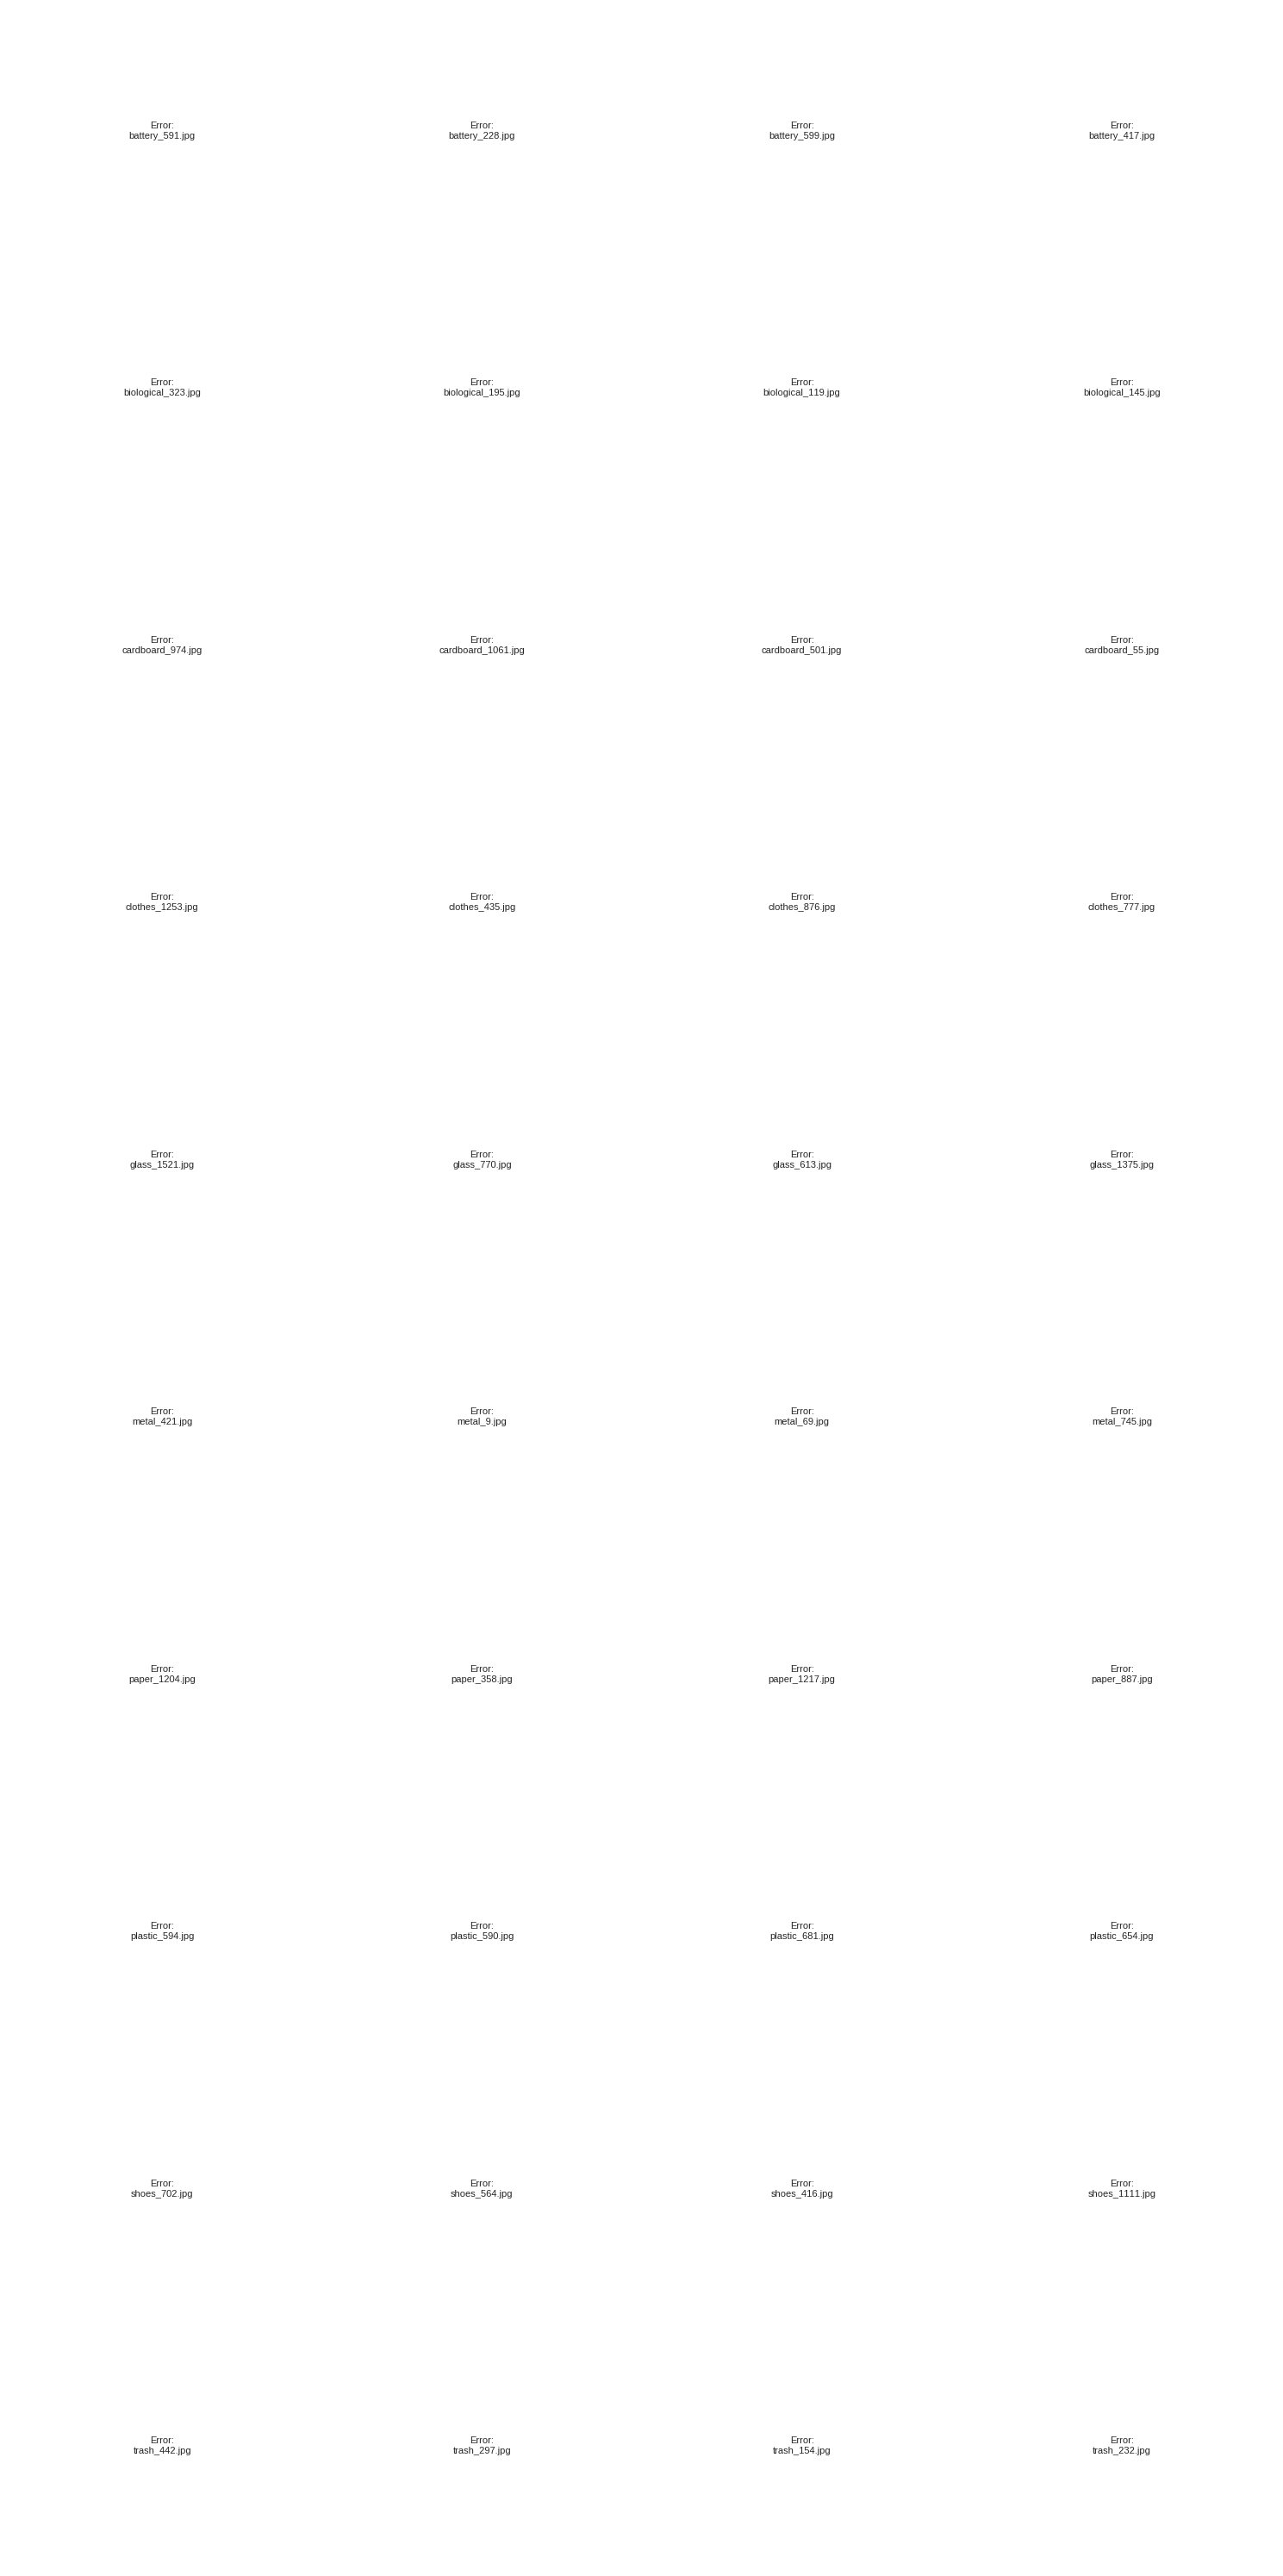

In [21]:
def mostrar_muestras_aleatorias(data_path, clases, num_muestras=4, figsize=(15, len(clases)*3)):
    """
    Muestra imágenes aleatorias de cada clase
    """
    if not clases:
        print("No hay clases para mostrar")
        return

    # Crear figura con subplots
    fig, axes = plt.subplots(len(clases), num_muestras, figsize=figsize, squeeze=False)  # Asegurar que axes sea 2D

    for i, clase in enumerate(clases):
        clase_path = os.path.join(data_path, clase)

        # Obtener todas las imágenes de la clase
        imagenes = [f for f in os.listdir(clase_path) if f.lower().endswith(('.jpg', '.png', '.jpeg', '.JPG', '.PNG'))]

        if len(imagenes) == 0:
            # Si no hay imágenes, mostrar placeholder
            for j in range(num_muestras):
                axes[i, j].text(0.5, 0.5, f'No hay imágenes\nen {clase}', ha='center', va='center', fontsize=10)
                axes[i, j].axis('off')
            continue

        # Seleccionar muestras aleatorias (sin reemplazo)
        if len(imagenes) >= num_muestras:
            muestras = random.sample(imagenes, num_muestras)
        else:
            # Si hay menos imágenes que las solicitadas, repetir algunas
            muestras = random.choices(imagenes, k=num_muestras)

        # Mostrar cada imagen
        for j, img_name in enumerate(muestras):
            img_path = os.path.join(clase_path, img_name)
            try:
                # Cargar imagen
                img = Image.open(img_path)

                # Mostrar en el subplot
                axes[i, j].imshow(img)
                axes[i, j].axis('off')

                # Añadir título con nombre de archivo (opcional)
                if j == 0:
                    axes[i, j].set_ylabel(clase, fontsize=10, rotation=0,
                                         ha='right', va='center', fontweight='bold')

                # Añadir tamaño de imagen como texto pequeño
                axes[i, j].text(0, 0, f'{img.size[0]}x{img.size[1]}',
                               fontsize=6, color='white',
                               bbox=dict(facecolor='black', alpha=0.5, pad=0))

            except Exception as e:
                axes[i, j].text(0.5, 0.5, f'Error:\n{img_name}',
                               ha='center', va='center', fontsize=8)
                axes[i, j].axis('off')
                print(f"  Error al cargar {img_name}: {e}")

    plt.tight_layout()
    plt.show()

# Mostrar muestras
mostrar_muestras_aleatorias(data_path, clases, num_muestras=4)

In [ ]:
def verificar_tamanos(data_path, clases, num_muestras=10):
    """
    Verifica que todas las imágenes tengan el tamaño esperado (384x384)
    """
    tamanos = set()

    for clase in clases[:3]:  # Solo verificar primeras 3 clases por eficiencia
        clase_path = os.path.join(data_path, clase)
        imagenes = [f for f in os.listdir(clase_path)
                   if f.lower().endswith(('.jpg', '.png', '.jpeg'))][:num_muestras]

        for img_name in imagenes:
            img_path = os.path.join(clase_path, img_name)
            try:
                with Image.open(img_path) as img:
                    tamanos.add(img.size)
            except:
                pass

    print(f"  Tamaños encontrados: {tamanos}")

    if len(tamanos) == 1 and list(tamanos)[0] == (384, 384):
        print("  Todas las imágenes son 384x384 píxeles")
    elif (384, 384) in tamanos:
        print("  La mayoría son 384x384, pero hay otros tamaños")
    else:
        print(f"  Tamaños detectados: {tamanos}")

verificar_tamanos(data_path, clases)

# Procesado de datos

In [ ]:
# Definir el mapeo de las 10 clases a las 4 categorías
mapeo_clases = {
    # Orgánico
    'biological': 'organico',  # Residuos biológicos/orgánicos

    # Papel/Cartón
    'cardboard': 'papel_carton',  # Cartón
    'paper': 'papel_carton',      # Papel

    # Vidrio
    'glass': 'vidrio',  # Vidrio

    # Plástico
    'plastic': 'plastico',  # Plástico

    # Nota: Las siguientes clases NO serán incluidas en el modelo de 4 clases
    # 'battery': No incluida (residuos peligrosos)
    # 'clothes': No incluida (textiles)
    # 'metal': No incluida (metal)
    # 'shoes': No incluida (calzado)
    # 'trash': No incluida (basura general)
}

# Nuestras 4 clases objetivo
clases_objetivo = ['organico', 'papel_carton', 'vidrio', 'plastico']

# Colores para visualización
colores_clases = {
    'organico': '#e74c3c',      # Verde
    'papel_carton': '#3498db',  # Azul
    'vidrio': '#2ecc71',        # Amarillo
    'plastico': '#f1c40f'       # Rojo
}

In [ ]:
def preparar_dataset_filtrado(data_path, mapeo_clases, clases_objetivo):
    """
    Filtra el dataset para solo las 4 clases deseadas
    """
    # Obtener todas las carpetas originales
    carpetas_originales = [d for d in os.listdir(data_path)
                          if os.path.isdir(os.path.join(data_path, d))]

    # Crear lista para almacenar rutas y etiquetas
    datos = []
    stats_original = {}

    for carpeta in carpetas_originales:
        ruta_carpeta = os.path.join(data_path, carpeta)
        num_imagenes = len([f for f in os.listdir(ruta_carpeta)
                           if f.lower().endswith(('.jpg', '.png', '.jpeg'))])
        stats_original[carpeta] = num_imagenes

        # Verificar si la clase debe ser incluida
        if carpeta in mapeo_clases:
            clase_destino = mapeo_clases[carpeta]
            print(f"{carpeta:<15} -> {clase_destino:<15} {num_imagenes:<8}")

            # Añadir todas las imágenes de esta carpeta
            for img_file in os.listdir(ruta_carpeta):
                if img_file.lower().endswith(('.jpg', '.png', '.jpeg')):
                    datos.append({
                        'filepath': os.path.join(ruta_carpeta, img_file),
                        'clase_original': carpeta,
                        'clase_objetivo': clase_destino
                    })
        else:
            print(f"{carpeta:<15} -> {'NO INCLUIDA':<15} {num_imagenes:<8}")

    # Crear DataFrame
    df = pd.DataFrame(datos)

    print("\n")
    for clase in clases_objetivo:
        count = len(df[df['clase_objetivo'] == clase])
        porcentaje = (count / len(df)) * 100 if len(df) > 0 else 0
        print(f"  {clase}: {count} imágenes ({porcentaje:.1f}%)")

    print(f"\nTotal imágenes para entrenamiento: {len(df)}")
    print(f"Reducción del dataset: {(1 - len(df)/sum(stats_original.values()))*100:.1f}%")

    return df, stats_original

# Preparar dataset filtrado
df, stats_original = preparar_dataset_filtrado(data_path, mapeo_clases, clases_objetivo)

# Visualizar distribución
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribución original (10 clases)
clases_orig = list(stats_original.keys())
valores_orig = list(stats_original.values())
colors_orig = plt.cm.Set3(np.linspace(0, 1, len(clases_orig)))
axes[0].barh(clases_orig, valores_orig, color=colors_orig)
axes[0].set_xlabel('Número de imágenes')
axes[0].set_title('Distribución original (10 clases)')
axes[0].axvline(x=sum(valores_orig)/len(valores_orig), color='red', linestyle='--', label='Media')
axes[0].legend()

# Gráfico 2: Distribución filtrada (4 clases)
dist_filtrada = df['clase_objetivo'].value_counts()
colors_filt = [colores_clases[clase] for clase in dist_filtrada.index]
axes[1].bar(dist_filtrada.index, dist_filtrada.values, color=colors_filt)
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Número de imágenes')
axes[1].set_title('Distribución para clasificación (4 clases)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

 # Clasificación

In [ ]:
import cv2 # Asegúrate de que OpenCV esté instalado (normalmente lo está en Colab)

def remove_simple_background(img_array):
    """
    Intenta eliminar fondos comunes (blanco/gris claro) de una imagen y los reemplaza con negro.
    Asume img_array es RGB en el rango [0, 255].
    Se puede personalizar el rango de colores de fondo a eliminar.

    Parámetros:
      img_array (numpy.ndarray): La imagen de entrada como array numpy (RGB, 0-255).

    Retorna:
      numpy.ndarray: La imagen con el fondo eliminado/negro.
    """

    # Rango para blanco/gris claro (valores altos en RGB).
    # Ajusta estos valores si tus fondos problemáticos tienen otros colores
    # Por ejemplo, para fondos marrones claros, podrías usar [100, 100, 80] y [200, 180, 150]
    # Para fondos rojizos, podrías usar [150, 100, 100] y [255, 150, 150]
    lower_bound = np.array([200, 200, 200], dtype=np.uint8) # Ej: Gris muy claro
    upper_bound = np.array([255, 255, 255], dtype=np.uint8) # Blanco puro

    # Crea una máscara donde los píxeles caen dentro del rango de color del fondo
    mask = cv2.inRange(img_array, lower_bound, upper_bound)

    # Crea una copia de la imagen y reemplaza los píxeles del fondo con negro (o el color deseado)
    output_img = np.copy(img_array)
    output_img[mask > 0] = [0, 0, 0] # Reemplazar el fondo detectado con negro

    return output_img

def crear_generadores(df, clases_objetivo, img_size=(224, 224), batch_size=32, train_ratio=0.7, val_ratio=0.15, test_ratio=0.15, preprocessing_func=None):
    """
    Crea generadores de datos para entrenamiento, validación y prueba
    """
    from sklearn.model_selection import train_test_split
    from tensorflow.keras.preprocessing.image import ImageDataGenerator

    if (train_ratio + val_ratio + test_ratio) != 1.0:
        raise ValueError("Los ratios de train, val y test deben sumar 1.0")

    # Primero, dividir el dataset en entrenamiento y un conjunto temporal para validación/prueba
    train_df, temp_df = train_test_split(
        df,
        test_size=(val_ratio + test_ratio),
        random_state=42,
        stratify=df['clase_objetivo']
    )

    # Luego, dividir el conjunto temporal en validación y prueba
    val_df, test_df = train_test_split(
        temp_df,
        test_size=(test_ratio / (val_ratio + test_ratio)),
        random_state=42,
        stratify=temp_df['clase_objetivo']
    )

    print(f"\nDivisión de datos:")
    print(f"  Entrenamiento: {len(train_df)} imágenes")
    print(f"  Validación: {len(val_df)} imágenes")
    print(f"  Prueba: {len(test_df)} imágenes")

    # Data augmentation para entrenamiento
    train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest',
        preprocessing_function=preprocessing_func # Aplica la función de preprocesamiento
    )

    # Solo escalado para validación y prueba
    val_test_datagen = ImageDataGenerator(
        rescale=1./255,
        preprocessing_function=preprocessing_func # Aplica la función de preprocesamiento
    )

    # Crear generadores
    train_generator = train_datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='filepath',
        y_col='clase_objetivo',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        classes=clases_objetivo,
        shuffle=True
    )

    val_generator = val_test_datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='filepath',
        y_col='clase_objetivo',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        classes=clases_objetivo,
        shuffle=False
    )

    test_generator = val_test_datagen.flow_from_dataframe(
        dataframe=test_df,
        x_col='filepath',
        y_col='clase_objetivo',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        classes=clases_objetivo,
        shuffle=False
    )

    return train_generator, val_generator, test_generator, train_df, val_df, test_df

# Parámetros
IMG_SIZE = (224, 224)  # Tamaño estándar para MobileNetV2
BATCH_SIZE = 32

# Crear generadores con 70/15/15 split, aplicando la eliminación de fondo
train_generator, val_generator, test_generator, train_df, val_df, test_df = crear_generadores(
    df, clases_objetivo, IMG_SIZE, BATCH_SIZE,
    train_ratio=0.7, val_ratio=0.15, test_ratio=0.15,
    preprocessing_func=remove_simple_background # Aquí se pasa la función
)

# Verificar clases
print(f"\nClases mapeadas: {train_generator.class_indices}")

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def construir_modelo_mobilenetv2(num_classes, input_shape=(224, 224, 3)):
    """
    Construye modelo con MobileNetV2 pre-entrenado y fine-tuning
    """
    # Cargar modelo base pre-entrenado en ImageNet
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )

    # Congelar capas base inicialmente
    base_model.trainable = False

    # Añadir capas personalizadas
    inputs = tf.keras.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x) # Corrected typo
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)

    return model, base_model

# Construir modelo
num_classes = len(clases_objetivo)
model, base_model = construir_modelo_mobilenetv2(num_classes, (*IMG_SIZE, 3))

# Compilar modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

model.summary()

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Callbacks para mejor entrenamiento
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'mejor_modelo_reciclaje.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Calcular pesos de clase para manejar desbalance
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(train_df['clase_objetivo'])
class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y_encoded),
    y=y_encoded
)
class_weight_dict = dict(enumerate(class_weights))

print("\nPesos de clase calculados:")
for i, clase in enumerate(train_generator.class_indices.keys()):
    print(f"  {clase}: {class_weight_dict[i]:.3f}")

In [ ]:
# Primera fase: entrenar solo las capas superiores
print("=== FASE 1: Entrenamiento de capas superiores ===")

history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stop, checkpoint, reduce_lr],
    class_weight=class_weight_dict,
    verbose=1
)

# Guardar historial
import pickle
with open('historial_entrenamiento.pkl', 'wb') as f:
    pickle.dump(history1.history, f)

In [ ]:
# === FASE 2: Fine-tuning (descongelar capas superiores) ===
print("=== FASE 2: Fine-tuning del modelo ===")

# Descongelar algunas capas del modelo base
base_model.trainable = True

# Congelar las primeras 100 capas (mantener características básicas)
for layer in base_model.layers[:100]:
    layer.trainable = False

# Recompilar con learning rate más bajo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # LR más bajo
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall']
)

# Continuar entrenamiento
history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,  # 20 épocas más
    callbacks=[early_stop, checkpoint, reduce_lr],
    class_weight=class_weight_dict,
    verbose=1
)

# Guardar historial combinado
with open('historial_entrenamiento_completo.pkl', 'wb') as f:
    combined_history = {
        'fase1': history1.history,
        'fase2': history2.history
    }
    pickle.dump(combined_history, f)

In [ ]:
# === GUARDAR MODELO EN DRIVE ===
from google.colab import drive
drive.mount('/content/drive')

# Guardar modelo completo
modelo_path = '/content/drive/MyDrive/modelo_reciclaje_final.h5'
model.save(modelo_path)
print(f"✅ Modelo guardado en: {modelo_path}")

# Guardar también los pesos por separado (opcional)
pesos_path = '/content/drive/MyDrive/pesos_reciclaje_final.weights.h5'
model.save_weights(pesos_path)

# Guardar el mapeo de clases
import json
class_indices = train_generator.class_indices
with open('/content/drive/MyDrive/clases_mapeo.json', 'w') as f:
    json.dump(class_indices, f)

print("✅ Mapeo de clases guardado")

# También puedes guardar en formato TensorFlow SavedModel (mejor para producción)
model.export('/content/drive/MyDrive/modelo_reciclaje_savedmodel')
print("✅ Modelo exportado en formato SavedModel")

## Evaluación del Modelo

In [ ]:
# === EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA ===
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("\n=== EVALUANDO EL MODELO EN EL CONJUNTO DE PRUEBA ===")

# Cargar el mejor modelo guardado (si se guardó con el callback ModelCheckpoint)
from tensorflow.keras.models import load_model
modelo_path = '/content/mejor_modelo_reciclaje.h5'
final_model = load_model(modelo_path)

# Evaluar en el test_generator
loss, accuracy, precision, recall = final_model.evaluate(test_generator, verbose=1)

print(f"\nResultados en el conjunto de prueba:")
print(f"  Loss: {loss:.4f}")
print(f"  Accuracy: {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall: {recall:.4f}")

# Generar predicciones para la matriz de confusión y el reporte de clasificación
print("\nGenerando predicciones para el conjunto de prueba...")
predictions = final_model.predict(test_generator, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# Reporte de clasificación
print("\n--- Reporte de Clasificación ---")
print(classification_report(y_true, y_pred, target_names=clases_objetivo))

# Matriz de confusión
print("\n--- Matriz de Confusión ---")
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=clases_objetivo, yticklabels=clases_objetivo)
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Verdadera')
plt.title('Matriz de Confusión')
plt.show()

print("✅ Evaluación completada en el conjunto de prueba.")


---

In [ ]:
# === CARGAR MODELO DESDE DRIVE Y PROBAR ===
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
import numpy as np

# Cargar modelo guardado
drive.mount('/content/drive')
modelo_cargado = load_model('/content/drive/MyDrive/modelo_reciclaje_final.h5')

# Cargar mapeo de clases
with open('/content/drive/MyDrive/clases_mapeo.json', 'r') as f:
    class_indices = json.load(f)
# Invertir el mapeo
idx_to_class = {v: k for k, v in class_indices.items()}

def predecir_imagen(ruta_imagen, model, idx_to_class, img_size=(224, 224)):
    """Predice la clase de una imagen"""
    # Cargar y preprocesar
    img = image.load_img(ruta_imagen, target_size=img_size)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0  # Normalizar igual que en entrenamiento

    # Predecir
    predicciones = model.predict(img_array, verbose=0)
    clase_idx = np.argmax(predicciones[0])
    confianza = predicciones[0][clase_idx]

    return idx_to_class[clase_idx], confianza, predicciones[0]

# === PROBAR CON UNA IMAGEN ===
# Sube una imagen manualmente a Colab o desde Drive
from google.colab import files
print("Sube una imagen de basura para probar:")
uploaded = files.upload()

for nombre_archivo in uploaded.keys():
    clase, confianza, todas_preds = predecir_imagen(nombre_archivo, modelo_cargado, idx_to_class)
    print(f"\n📸 Imagen: {nombre_archivo}")
    print(f"♻️ Predicción: {clase}")
    print(f"📊 Confianza: {confianza:.2%}")

    # Mostrar todas las probabilidades
    print("\nProbabilidades por clase:")
    for clase_name, prob in zip(idx_to_class.values(), todas_preds):
        print(f"  {clase_name}: {prob:.2%}")